In [60]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [61]:
df = pd.read_csv("Electricity_consumption.csv")
df.head()

,Timestamp,Temperature,Humidity,SquareFootage,Occupancy,HVACUsage,LightingUsage,RenewableEnergy,DayOfWeek,Holiday,ElectricityConsumption
0,01-01-2022 00:00,25.139433,43.431581,1565.693999,5,On,Off,2.774699,Monday,No,75.364373
1,01-01-2022 01:00,27.731651,54.225919,1411.064918,1,On,On,21.831384,Saturday,No,83.401855
2,01-01-2022 02:00,28.704277,58.907658,1755.715009,2,Off,Off,6.764672,Sunday,No,78.270888
3,01-01-2022 03:00,20.080469,50.371637,1452.316318,1,Off,On,8.623447,Wednesday,No,56.519850
4,01-01-2022 04:00,23.097359,51.401421,1094.130359,9,On,Off,3.071969,Friday,No,70.811732


In [62]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

Shape: (1000, 11)

Columns:
['Timestamp', 'Temperature', 'Humidity', 'SquareFootage', 'Occupancy', 'HVACUsage', 'LightingUsage', 'RenewableEnergy', 'DayOfWeek', 'Holiday', 'ElectricityConsumption']

Data Types:
Timestamp                  object
Temperature               float64
Humidity                  float64
SquareFootage             float64
Occupancy                   int64
HVACUsage                  object
LightingUsage              object
RenewableEnergy           float64
DayOfWeek                  object
Holiday                    object
ElectricityConsumption    float64
dtype: object


In [63]:
df.isnull().sum()

,0
Timestamp,0
Temperature,0
Humidity,0
SquareFootage,0
Occupancy,0
HVACUsage,0
LightingUsage,0
RenewableEnergy,0
DayOfWeek,0
Holiday,0


In [64]:
df = pd.get_dummies(
    df,
    columns=['HVACUsage', 'LightingUsage', 'DayOfWeek', 'Holiday'],
    drop_first=True,
    dtype=int
)

df.head()

,Timestamp,Temperature,Humidity,SquareFootage,Occupancy,RenewableEnergy,ElectricityConsumption,HVACUsage_On,LightingUsage_On,DayOfWeek_Monday,DayOfWeek_Saturday,DayOfWeek_Sunday,DayOfWeek_Thursday,DayOfWeek_Tuesday,DayOfWeek_Wednesday,Holiday_Yes
0,01-01-2022 00:00,25.139433,43.431581,1565.693999,5,2.774699,75.364373,1,0,1,0,0,0,0,0,0
1,01-01-2022 01:00,27.731651,54.225919,1411.064918,1,21.831384,83.401855,1,1,0,1,0,0,0,0,0
2,01-01-2022 02:00,28.704277,58.907658,1755.715009,2,6.764672,78.270888,0,0,0,0,1,0,0,0,0
3,01-01-2022 03:00,20.080469,50.371637,1452.316318,1,8.623447,56.519850,0,1,0,0,0,0,0,1,0
4,01-01-2022 04:00,23.097359,51.401421,1094.130359,9,3.071969,70.811732,1,0,0,0,0,0,0,0,0


In [65]:
print("Dataset Summary:")
display(df.describe())

Dataset Summary:


,Temperature,Humidity,SquareFootage,Occupancy,RenewableEnergy,ElectricityConsumption,HVACUsage_On,LightingUsage_On,DayOfWeek_Monday,DayOfWeek_Saturday,DayOfWeek_Sunday,DayOfWeek_Thursday,DayOfWeek_Tuesday,DayOfWeek_Wednesday,Holiday_Yes
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,24.982026,45.395412,1500.052488,4.581000,15.132813,77.055873,0.492000,0.491000,0.123000,0.143000,0.154000,0.146000,0.146000,0.124000,0.467000
std,2.836850,8.518905,288.418873,2.865598,8.745917,8.144112,0.500186,0.500169,0.328602,0.350248,0.361129,0.353283,0.353283,0.329746,0.499159
min,20.007565,30.015975,1000.512661,0.000000,0.006642,53.263278,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,22.645070,38.297722,1247.108548,2.000000,7.628385,71.544690,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,24.751637,45.972116,1507.967426,5.000000,15.072296,76.943696,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,27.418174,52.420066,1740.340165,7.000000,22.884064,82.921742,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
max,29.998671,59.969085,1999.982252,9.000000,29.965327,99.201120,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


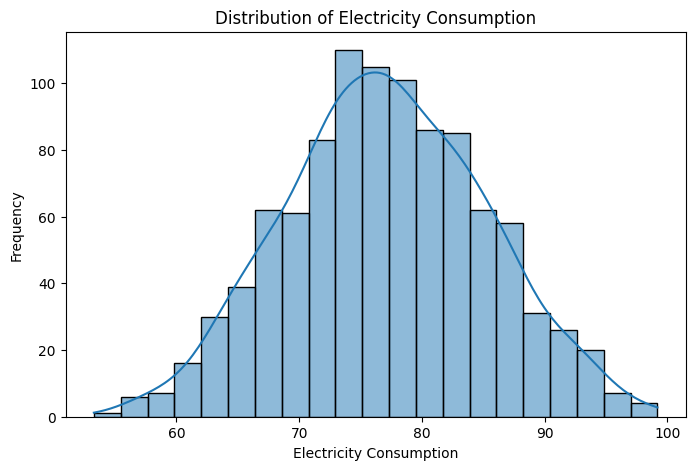

In [66]:
plt.figure(figsize=(8, 5))
sns.histplot(df['ElectricityConsumption'], kde=True)
plt.title('Distribution of Electricity Consumption')
plt.xlabel('Electricity Consumption')
plt.ylabel('Frequency')
plt.show()

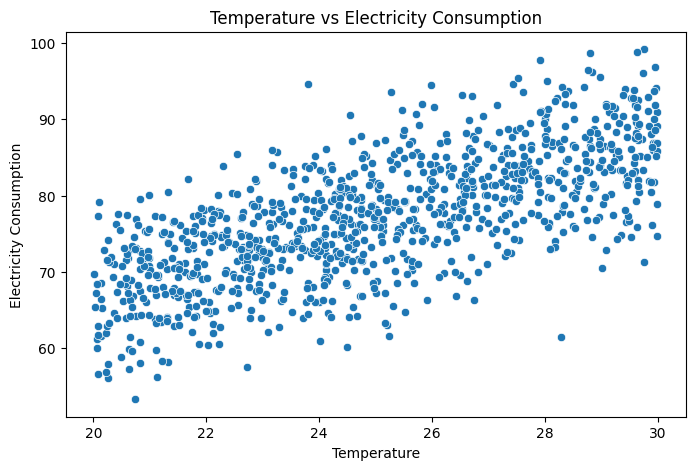

In [67]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x='Temperature',
    y='ElectricityConsumption'
)
plt.title('Temperature vs Electricity Consumption')
plt.xlabel('Temperature')
plt.ylabel('Electricity Consumption')
plt.show()

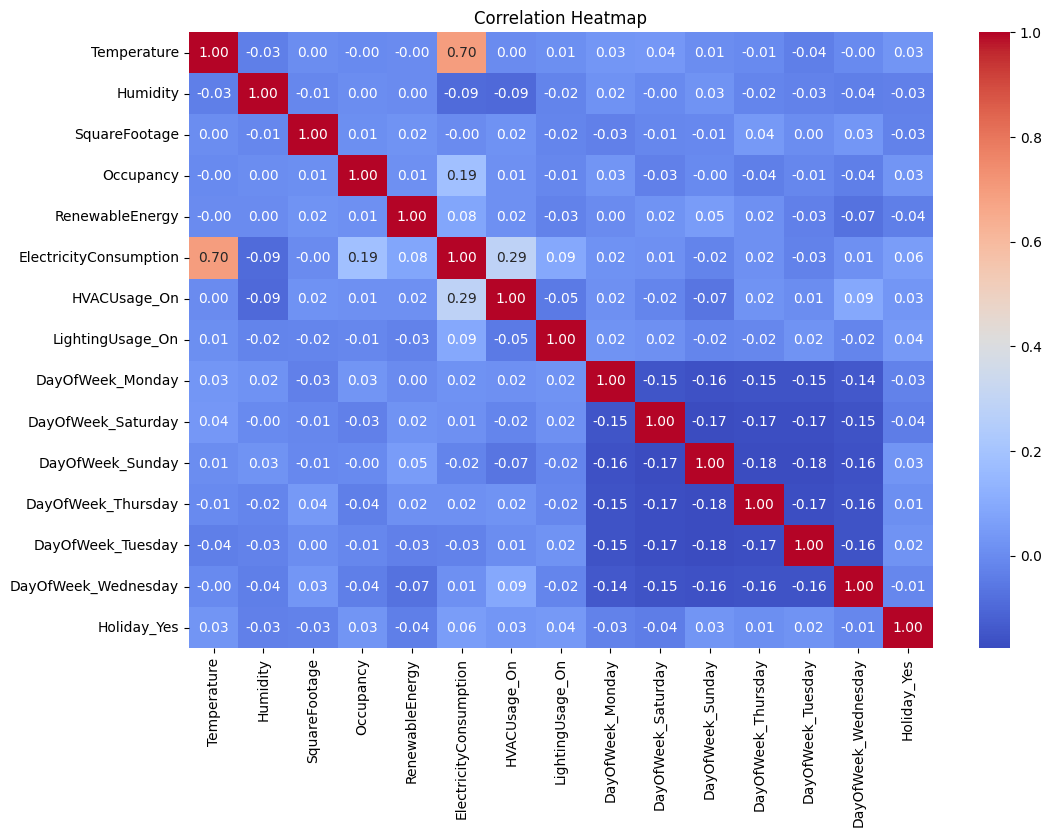

In [68]:
plt.figure(figsize=(12, 8))
sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    fmt='.2f',
    cmap='coolwarm'
)
plt.title('Correlation Heatmap')
plt.show()

In [69]:
from sklearn.model_selection import train_test_split
X = df.drop('ElectricityConsumption', axis=1)
y = df['ElectricityConsumption']
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)
print("Total samples:", len(df))
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Number of features:", X_train.shape[1])

Total samples: 1000
Training samples: 800
Testing samples: 200
Number of features: 15


In [70]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# Drop non-numeric 'Timestamp' column if it's present in the training features
X_train_numeric = X_train.drop(columns=['Timestamp'], errors='ignore')
X_test_numeric = X_test.drop(columns=['Timestamp'], errors='ignore')

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        random_state=42
    )
}

trained_models = {}
for name, model in models.items():
    model.fit(X_train_numeric, y_train)
    trained_models[name] = model
    print(f"{name} trained successfully!")

print("\nAll 4 models trained successfully.")

Linear Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!
Gradient Boosting trained successfully!

All 4 models trained successfully.


In [71]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
results = []
for name, model in trained_models.items():
    # Use X_test_numeric instead of X_test to match the training features
    y_pred = model.predict(X_test_numeric)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Algorithm": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })
results_df = pd.DataFrame(results)
display(results_df)

,Algorithm,MAE,RMSE,R2 Score
0,Linear Regression,4.120283,5.152376,0.594702
1,Decision Tree,5.889538,7.426252,0.158025
2,Random Forest,4.337342,5.407168,0.553626
3,Gradient Boosting,4.438666,5.542997,0.530918


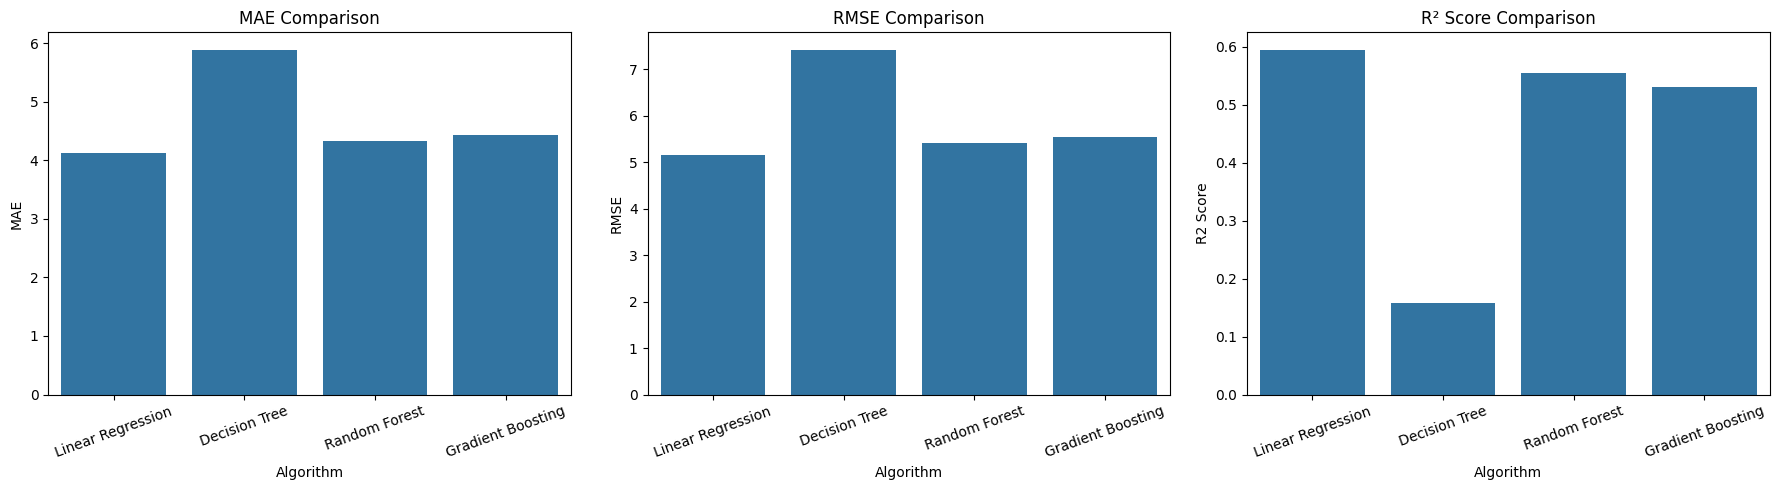

In [72]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.barplot(data=results_df, x='Algorithm', y='MAE', ax=axes[0])
axes[0].set_title('MAE Comparison')
axes[0].tick_params(axis='x', rotation=20)

sns.barplot(data=results_df, x='Algorithm', y='RMSE', ax=axes[1])
axes[1].set_title('RMSE Comparison')
axes[1].tick_params(axis='x', rotation=20)

sns.barplot(data=results_df, x='Algorithm', y='R2 Score', ax=axes[2])
axes[2].set_title('R² Score Comparison')
axes[2].tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()

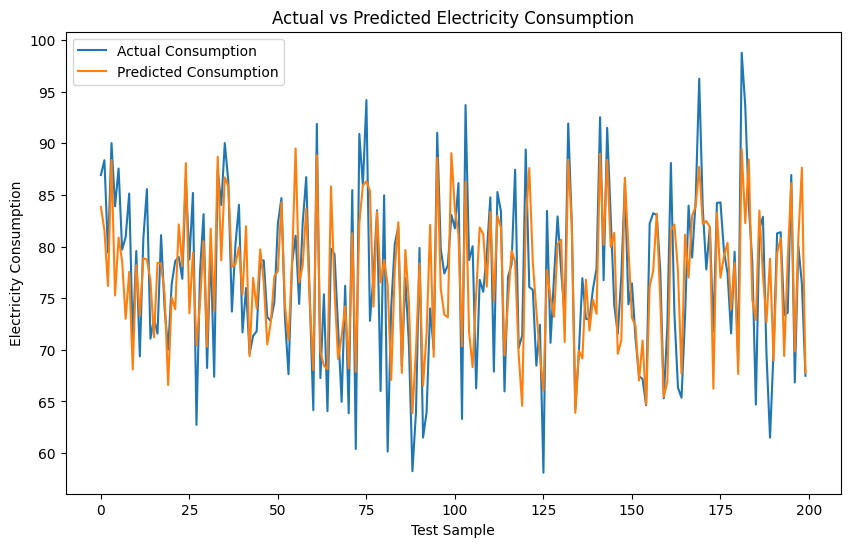

In [73]:
model = trained_models["Linear Regression"]
# Use X_test_numeric instead of X_test to match the training features
y_pred = model.predict(X_test_numeric)
plt.figure(figsize=(10, 6))
plt.plot(
    range(len(y_test)),
    y_test.values,
    label='Actual Consumption'
)
plt.plot(
    range(len(y_pred)),
    y_pred,
    label='Predicted Consumption'
)
plt.title('Actual vs Predicted Electricity Consumption')
plt.xlabel('Test Sample')
plt.ylabel('Electricity Consumption')
plt.legend()
plt.show()

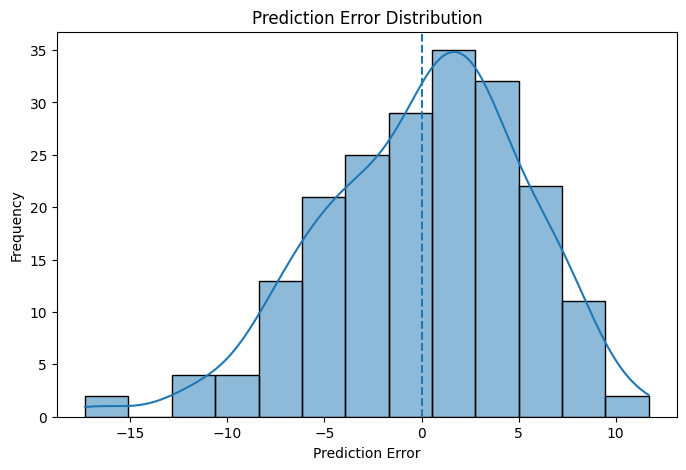

In [74]:
errors = y_test.values - y_pred
plt.figure(figsize=(8, 5))
sns.histplot(errors, kde=True)
plt.title('Prediction Error Distribution')
plt.xlabel('Prediction Error')
plt.ylabel('Frequency')
plt.axvline(0, linestyle='--')
plt.show()

In [75]:
new_data = {
    'Temperature': 25,
    'Humidity': 50,
    'SquareFootage': 1500,
    'Occupancy': 4,
    'RenewableEnergy': 10,
    'Hour': 18,
    'Day': 15,
    'Month': 6,
    'DayOfWeek_Num': 2
}
new_input = pd.DataFrame([new_data])
# Align columns with X_train_numeric.columns (which excludes 'Timestamp')
for column in X_train_numeric.columns:
    if column not in new_input.columns:
        new_input[column] = 0
new_input = new_input[X_train_numeric.columns]
prediction = trained_models['Linear Regression'].predict(new_input)[0]
print("Predicted Electricity Consumption:", round(prediction, 2))

Predicted Electricity Consumption: 72.76


In [76]:
results_df.to_csv("model_comparison_results.csv", index=False)
print("Model comparison results saved successfully.")
display(results_df)

Model comparison results saved successfully.


,Algorithm,MAE,RMSE,R2 Score
0,Linear Regression,4.120283,5.152376,0.594702
1,Decision Tree,5.889538,7.426252,0.158025
2,Random Forest,4.337342,5.407168,0.553626
3,Gradient Boosting,4.438666,5.542997,0.530918


In [77]:
print("=" * 60)
print("ELECTRICITY CONSUMPTION PREDICTION - FINAL RESULTS")
print("=" * 60)
print("\nDataset Shape:", df.shape)
print("Number of Features:", X.shape[1])
print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))
print("\nModel Performance:")
display(
    results_df.sort_values(
        by="R2 Score",
        ascending=False
    ).reset_index(drop=True)
)
print("\nExample Prediction:")
print("Predicted Electricity Consumption:", round(prediction, 2))

ELECTRICITY CONSUMPTION PREDICTION - FINAL RESULTS

Dataset Shape: (1000, 16)
Number of Features: 15
Training Samples: 800
Testing Samples: 200

Model Performance:


,Algorithm,MAE,RMSE,R2 Score
0,Linear Regression,4.120283,5.152376,0.594702
1,Random Forest,4.337342,5.407168,0.553626
2,Gradient Boosting,4.438666,5.542997,0.530918
3,Decision Tree,5.889538,7.426252,0.158025



Example Prediction:
Predicted Electricity Consumption: 72.76
